# importing libraries

In [54]:
import pandas as pd
import numpy as np
import matplotlib as mlt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.metrics import accuracy_score
%pip install scikit-learn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

Note: you may need to restart the kernel to use updated packages.


In [55]:
import os

print(os.getcwd())
print(os.listdir())

d:\E-Commerce-Sales-Customer-Intelligence\notebooks
['Intelligence (2).ipynb']


# Load the datasets

In [56]:
import pandas as pd

customers = pd.read_csv("../data/customers_dataset.csv")
orders = pd.read_csv("../data/orders_dataset.csv")
items = pd.read_csv("../data/order_items_dataset.csv")
products = pd.read_csv("../data/products_dataset.csv")
reviews = pd.read_csv("../data/order_reviews_dataset.csv")
# Check the datasets
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Products:", products.shape)
print("Reviews:", reviews.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Items: (112650, 7)
Products: (32951, 9)
Reviews: (99224, 7)


# Check missing values

In [57]:
print("Customers missing values:")
print(customers.isnull().sum())

print("\nOrders missing values:")
print(orders.isnull().sum())

print("\nProducts missing values:")
print(products.isnull().sum())

Customers missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Orders missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Products missing values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


# Check column names


In [58]:
print("CUSTOMERS")
print(customers.columns.tolist())

print("\nORDERS")
print(orders.columns.tolist())

print("\nORDER ITEMS")
print(items.columns.tolist())

print("\nPRODUCTS")
print(products.columns.tolist())

CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


#  Check duplicate records

In [59]:
print("Duplicate customers:", customers.duplicated().sum())
print("Duplicate orders:", orders.duplicated().sum())
print("Duplicate products:", products.duplicated().sum())

Duplicate customers: 0
Duplicate orders: 0
Duplicate products: 0


# Check missing values

In [60]:
missing = pd.DataFrame({
    "Customers": customers.isnull().sum(),
    "Orders": orders.isnull().sum(),
    "Order_Items": items.isnull().sum(),
    "Products": products.isnull().sum()
})

missing

,Customers,Orders,Order_Items,Products
customer_city,0.0,NaN,NaN,NaN
customer_id,0.0,0.0,NaN,NaN
customer_state,0.0,NaN,NaN,NaN
customer_unique_id,0.0,NaN,NaN,NaN
customer_zip_code_prefix,0.0,NaN,NaN,NaN
freight_value,NaN,NaN,0.0,NaN
order_approved_at,NaN,160.0,NaN,NaN
order_delivered_carrier_date,NaN,1783.0,NaN,NaN
order_delivered_customer_date,NaN,2965.0,NaN,NaN
order_estimated_delivery_date,NaN,0.0,NaN,NaN


In [61]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

# Convert order date

In [62]:
# Convert date columns to datetime

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

In [63]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                           str
order_delivered_carrier_date                str
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

# First visualization

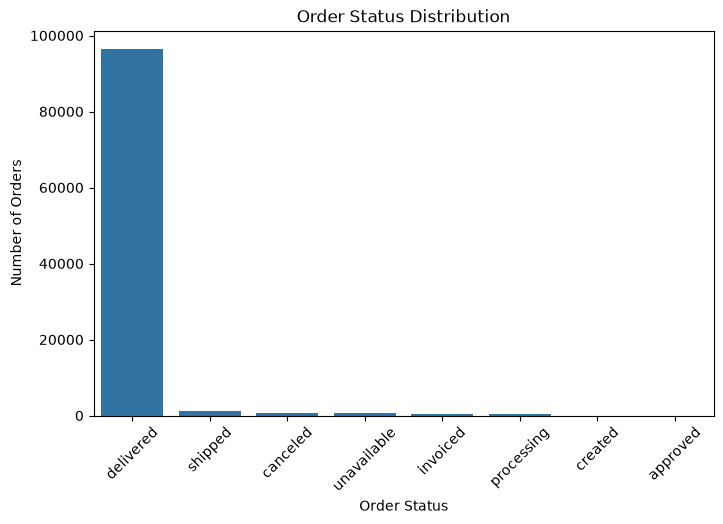

In [64]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=orders,
    x="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

# Our first business question

# calculate total orders:

In [65]:
total_orders = orders["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 99441


In [66]:
# delivered orders:

In [67]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
]["order_id"].nunique()

print("Delivered Orders:", delivered_orders)

Delivered Orders: 96478


In [68]:
# Create the sales dataset

In [69]:
sales = orders.merge(
    items,
    on="order_id",
    how="inner"
)

print("Sales dataset shape:", sales.shape)
sales.head()

Sales dataset shape: (112650, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [70]:
sales = sales.merge(
    products,
    on="product_id",
    how="left"
)

print("After merging products:", sales.shape)
sales.head()

After merging products: (112650, 22)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


# Calculate Revenue

In [71]:
sales["revenue"] = sales["price"]

In [72]:
sales[["order_id", "product_id", "price", "revenue"]].head()

,order_id,product_id,price,revenue
0,e481f51cbdc54678b7cc49136f2d6af7,87285b34884572647811a353c7ac498a,29.99,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,595fac2a385ac33a80bd5114aec74eb8,118.70,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,aa4383b373c6aca5d8797843e5594415,159.90,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,65266b2da20d04dbe00c5c2d3bb7859e,19.90,19.90


# Total revenue

In [73]:
total_revenue = sales["revenue"].sum()

print("Total Revenue: ₹", round(total_revenue, 2))

Total Revenue: ₹ 13591643.7


# Top 10 products

In [74]:
top_products = (
    sales.groupby("product_category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: revenue, dtype: float64

# Monthly sales

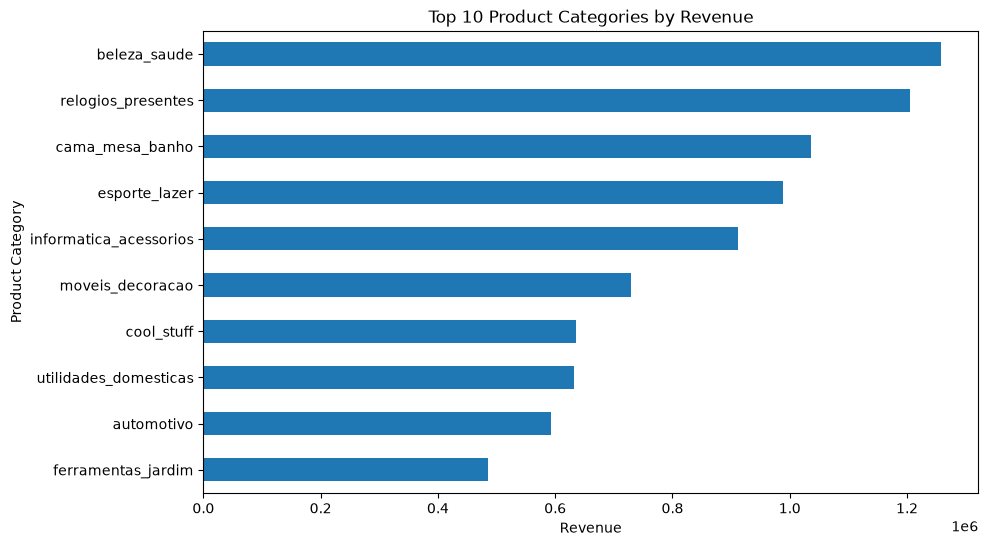

In [75]:
plt.figure(figsize=(10,6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.show()

 # Monthly sales

In [76]:
sales["month"] = sales["order_purchase_timestamp"].dt.to_period("M")

In [77]:
monthly_sales = (
    sales.groupby("month")["revenue"]
    .sum()
)

monthly_sales

month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: revenue, dtype: float64

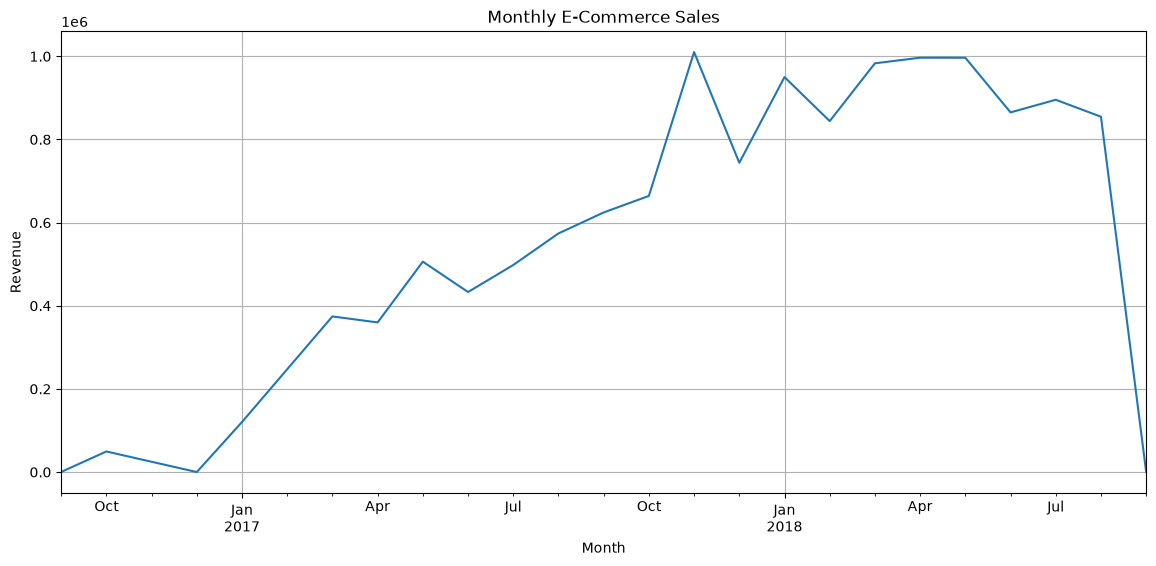

In [78]:
plt.figure(figsize=(14,6))

monthly_sales.plot()

plt.title("Monthly E-Commerce Sales")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.grid()
plt.show()

Customer Intelligence Dataset

In [79]:
customer_sales = sales.merge(
    customers,
    on="customer_id",
    how="left"
)

customer_sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,revenue,month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,500.0,19.0,8.0,13.0,29.99,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,400.0,19.0,13.0,19.0,118.70,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,420.0,24.0,19.0,21.0,159.90,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,450.0,30.0,10.0,20.0,45.00,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,250.0,51.0,15.0,15.0,19.90,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


MERGING ORDERS AND ORDER ITEMS AND KEEPING THE MERGE VALUE IN SALES

In [80]:
# Create the sales dataset
sales = orders.merge(
    items,
    on="order_id",
    how="inner"
)

print("Sales dataset shape:", sales.shape)
sales.head()

Sales dataset shape: (112650, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


MERGING THE SALES ABOVE WITH THE PRODUCTS USING PRODUCT_ID

In [81]:
sales = sales.merge(
    products,
    on="product_id",
    how="left"
)

print("Sales dataset after adding products:", sales.shape)
sales.head()

Sales dataset after adding products: (112650, 22)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


In [82]:
print("Missing order IDs:", sales["order_id"].isnull().sum())
print("Missing product IDs:", sales["product_id"].isnull().sum())
print("Missing prices:", sales["price"].isnull().sum())
print("Duplicate rows:", sales.duplicated().sum())

Missing order IDs: 0
Missing product IDs: 0
Missing prices: 0
Duplicate rows: 0


MERGING ABOVE SALES WITH CUSTOMER ON CUSTOMER_ID TO GET CUSTOMER SALES DATASET

In [84]:
# Create Customer Intelligence dataset

customer_sales = sales.merge(
    customers,
    on="customer_id",
    how="left"
)

print("Customer Sales shape:", customer_sales.shape)

customer_sales.head()

Customer Sales shape: (112650, 26)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,178.0,1.0,400.0,19.0,13.0,19.0,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,232.0,1.0,420.0,24.0,19.0,21.0,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,468.0,3.0,450.0,30.0,10.0,20.0,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,316.0,4.0,250.0,51.0,15.0,15.0,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [86]:
print(customer_sales.shape)

(112650, 26)


In [85]:
print(customer_sales.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


In [88]:
print(customer_sales[["price", "revenue"]].head())

    price  revenue
0   29.99    29.99
1  118.70   118.70
2  159.90   159.90
3   45.00    45.00
4   19.90    19.90


In [90]:
customer_summary = customer_sales.groupby("customer_unique_id").agg(
    total_orders=("order_id", "nunique"),
    total_spend=("revenue", "sum"),
    average_order_value=("revenue", "mean"),
    total_items=("order_item_id", "count")
).reset_index()

print("Customer summary shape:", customer_summary.shape)
print(customer_summary.head())

Customer summary shape: (95420, 5)
                 customer_unique_id  total_orders  total_spend  \
0  0000366f3b9a7992bf8c76cfdf3221e2             1       129.90   
1  0000b849f77a49e4a4ce2b2a4ca5be3f             1        18.90   
2  0000f46a3911fa3c0805444483337064             1        69.00   
3  0000f6ccb0745a6a4b88665a16c9f078             1        25.99   
4  0004aac84e0df4da2b147fca70cf8255             1       180.00   

   average_order_value  total_items  
0               129.90            1  
1                18.90            1  
2                69.00            1  
3                25.99            1  
4               180.00            1  


In [91]:
print(customer_summary.describe())

       total_orders   total_spend  average_order_value  total_items
count  95420.000000  95420.000000         95420.000000  95420.00000
mean       1.034018    142.440198           126.516509      1.18057
std        0.211234    217.656355           191.743686      0.62145
min        1.000000      0.850000             0.850000      1.00000
25%        1.000000     47.900000            42.900000      1.00000
50%        1.000000     89.900000            79.080000      1.00000
75%        1.000000    155.000000           139.900000      1.00000
max       16.000000  13440.000000          6735.000000     24.00000


In [92]:
# Classify customers based on number of orders

customer_summary["customer_type"] = np.where(
    customer_summary["total_orders"] == 1,
    "One-time Customer",
    "Repeat Customer"
)

print(customer_summary["customer_type"].value_counts())

customer_type
One-time Customer    92507
Repeat Customer       2913
Name: count, dtype: int64


How many customers purchased once vs coming back for additional orders

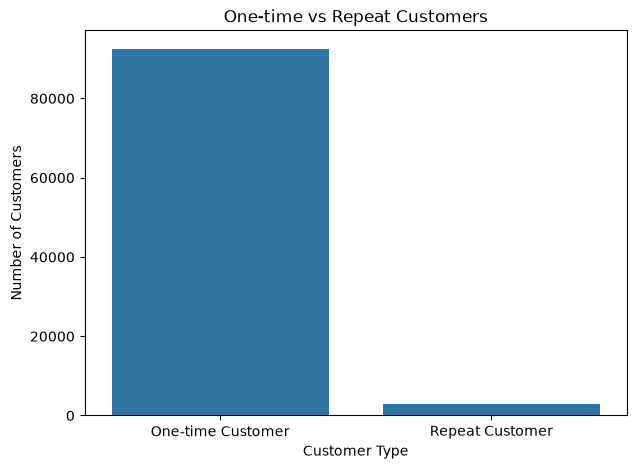

In [93]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=customer_summary,
    x="customer_type"
)

plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.show()

top 10 customers by spending

In [95]:
top_customers = (
    customer_summary
    .sort_values("total_spend", ascending=False)
    .head(10)
)

top_customers[
    ["customer_unique_id", "total_orders", "total_spend", "total_items"]
]

,customer_unique_id,total_orders,total_spend,total_items
3799,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,8
81388,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,2
44139,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,4
82230,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,1
26015,459bef486812aa25204be022145caa62,1,6729.0,1
95131,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0,1
23947,4007669dec559734d6f53e029e360987,1,5934.6,6
89056,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0,1
34820,5d0a2980b292d049061542014e8960bf,1,4599.9,2
27242,48e1ac109decbb87765a3eade6854098,1,4590.0,1


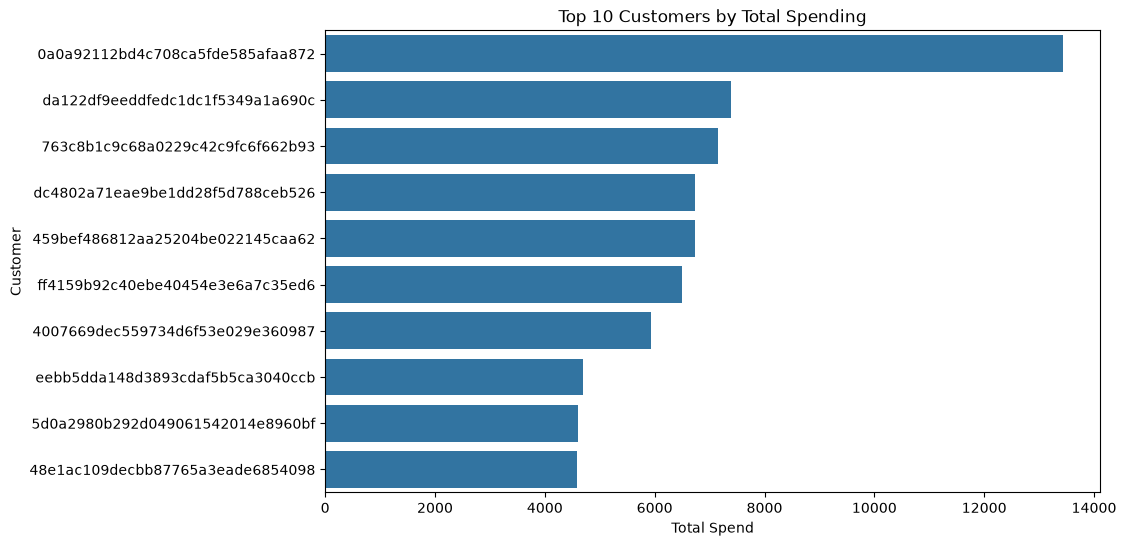

In [96]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_customers,
    x="total_spend",
    y="customer_unique_id"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spend")
plt.ylabel("Customer")

plt.show()

CUSTOMER LOCATION ANALYSIS

In [97]:
customer_location = (
    customers.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(customer_location)

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
PE     1609
CE     1313
PA      949
MT      876
MA      726
MS      694
PB      519
PI      482
RN      474
AL      401
SE      342
TO      273
RO      240
AM      143
AC       77
AP       67
RR       45
Name: customer_unique_id, dtype: int64


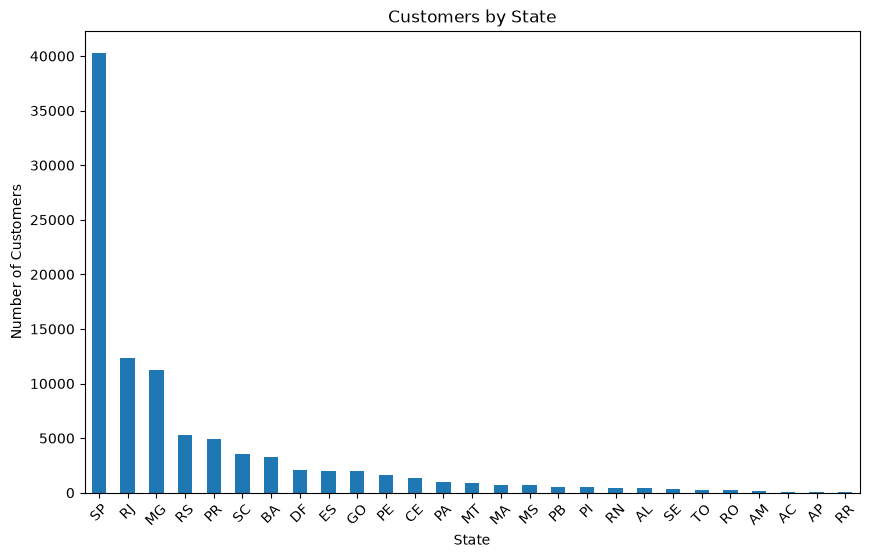

In [98]:
plt.figure(figsize=(10, 6))

customer_location.plot(kind="bar")

plt.title("Customers by State")
plt.xlabel("State")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.show()

In [129]:
top_states = customer_state.head(10)

print(top_states)

customer_state
SP    39981
RJ    12303
MG    11178
RS     5249
PR     4840
SC     3513
BA     3257
DF     2062
ES     1956
GO     1942
Name: customer_unique_id, dtype: int64


HOW OFTEN CUSTOMERS PURCHASE

In [99]:
purchase_frequency = (
    customer_summary["total_orders"]
    .value_counts()
    .sort_index()
)

print(purchase_frequency)

total_orders
1     92507
2      2673
3       192
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64


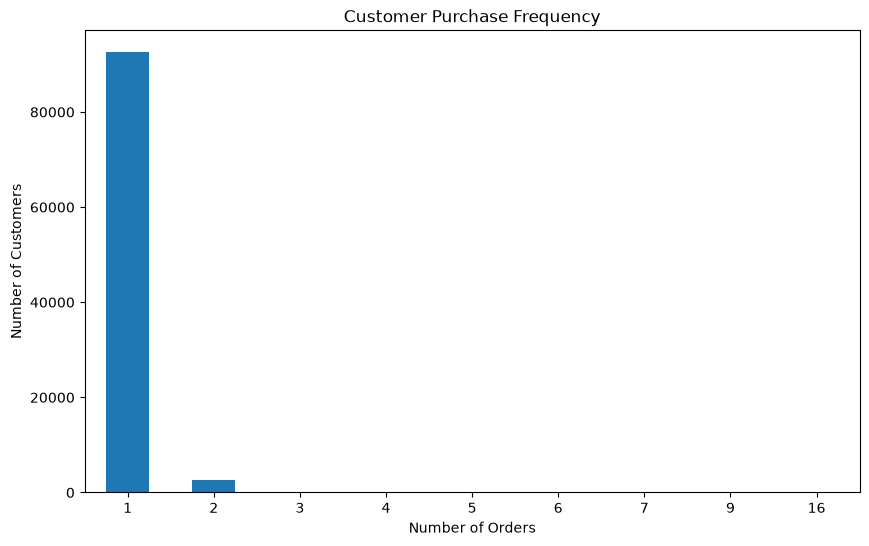

In [100]:
plt.figure(figsize=(10, 6))

purchase_frequency.plot(kind="bar")

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)
plt.show()

In [101]:
total_customers = len(customer_summary)

repeat_customers = (
    customer_summary["total_orders"] > 1
).sum()

repeat_percentage = (repeat_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("Repeat Customer Percentage:", round(repeat_percentage, 2), "%")

Total Customers: 95420
Repeat Customers: 2913
Repeat Customer Percentage: 3.05 %


Repeat Customer Percentage is a CUSTOMER PERFORMANCE KPI(is basically a key performance indicator that measure and understand about customer behaviour)

In [ ]:
RFM = Recency + Frequency + Monetary

Recency: How recently did the customer purchase?
Frequency: How many orders did the customer make?
Monetary: How much did the customer spend?

In [102]:
analysis_date = orders["order_purchase_timestamp"].max()

print("Analysis Date:", analysis_date)

Analysis Date: 2018-10-17 17:30:18


In [103]:
rfm = customer_sales.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp",
             lambda x: (analysis_date - x.max()).days),
    
    Frequency=("order_id", "nunique"),
    
    Monetary=("revenue", "sum")
).reset_index()

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,160,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,18.90
2,0000f46a3911fa3c0805444483337064,585,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,369,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,336,1,180.00


In [ ]:
print("RFM dataset shape:", rfm.shape)
print(rfm.describe())

RFM dataset shape: (95420, 4)
            Recency     Frequency      Monetary
count  95420.000000  95420.000000  95420.000000
mean     287.128118      1.034018    142.440198
std      153.157768      0.211234    217.656355
min       44.000000      1.000000      0.850000
25%      163.000000      1.000000     47.900000
50%      268.000000      1.000000     89.900000
75%      396.000000      1.000000    155.000000
max      772.000000     16.000000  13440.000000


In [ ]:
CONVERTING RFM VALUES INTO SCORE

In [117]:
# Create RFM scores

rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head()




,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,160,1,129.90,4,1,4,9,Potential
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,18.90,4,1,1,6,At Risk
2,0000f46a3911fa3c0805444483337064,585,1,69.00,1,1,2,4,Low Value
3,0000f6ccb0745a6a4b88665a16c9f078,369,1,25.99,2,1,1,4,Low Value
4,0004aac84e0df4da2b147fca70cf8255,336,1,180.00,2,1,5,8,Potential


CUSTOMER SEGMENTS

In [124]:
def customer_segment(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["M_Score"] >= 4 and row["R_Score"] >= 3:
        return "High Spenders"

    elif row["R_Score"] >= 4:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "At Risk"

    else:
        return "Regular Customers"


rfm["Customer_Segment"] = rfm.apply(
    customer_segment,
    axis=1
)

print(rfm["Customer_Segment"].value_counts())

Customer_Segment
Regular Customers    34234
Recent Customers     22522
High Spenders        16760
At Risk              15279
Champions             6625
Name: count, dtype: int64


In [125]:
segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customers=("customer_unique_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .sort_values("Customers", ascending=False)
)

segment_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Customer_Segment,,,,
Regular Customers,34234,385.574750,1.036280,115.003323
Recent Customers,22522,138.588713,1.013010,55.932462
High Spenders,16760,199.399045,1.032697,262.217570
At Risk,15279,445.509457,1.000000,141.402038
Champions,6625,140.050868,1.175547,277.684654


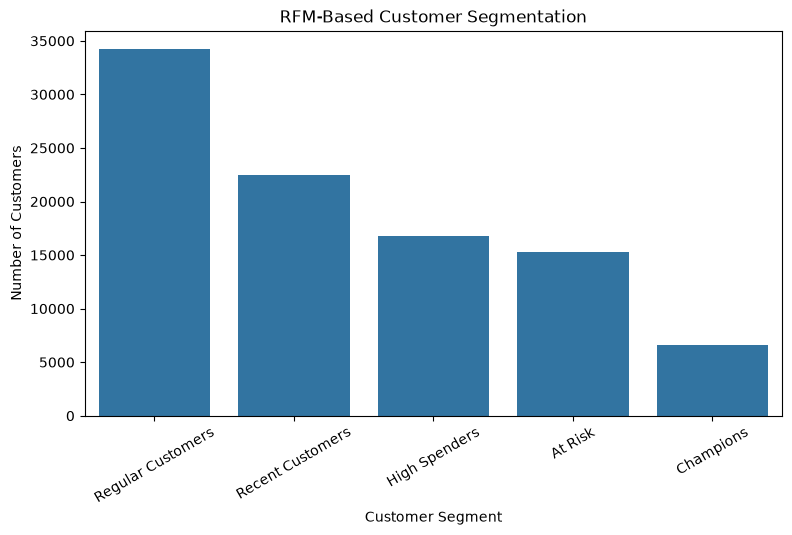

In [126]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_summary.reset_index(),
    x="Customer_Segment",
    y="Customers"
)

plt.title("RFM-Based Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [122]:
rfm_score_distribution = (
    rfm["RFM_Score"]
    .value_counts()
    .sort_index()
)

print(rfm_score_distribution)

RFM_Score
3       866
4      2452
5      4830
6      7839
7     11433
8     13572
9     14323
10    13393
11    11045
12     7560
13     4681
14     2433
15      993
Name: count, dtype: int64


In [123]:
print("Recency scores:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nFrequency scores:")
print(rfm["F_Score"].value_counts().sort_index())

print("\nMonetary scores:")
print(rfm["M_Score"].value_counts().sort_index())

Recency scores:
R_Score
5    19129
4    19189
3    19126
2    18936
1    19040
Name: count, dtype: int64

Frequency scores:
F_Score
1    19084
2    19084
3    19084
4    19084
5    19084
Name: count, dtype: int64

Monetary scores:
M_Score
1    19728
2    19815
3    17792
4    19051
5    19034
Name: count, dtype: int64


REVENUE BY CUSTOMER STATE

In [131]:
state_revenue = (
    customer_sales.groupby("customer_state")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(state_revenue.head(10))

customer_state
SP    5202955.05
RJ    1824092.67
MG    1585308.03
RS     750304.02
PR     683083.76
SC     520553.34
BA     511349.99
DF     302603.94
GO     294591.95
ES     275037.31
Name: revenue, dtype: float64


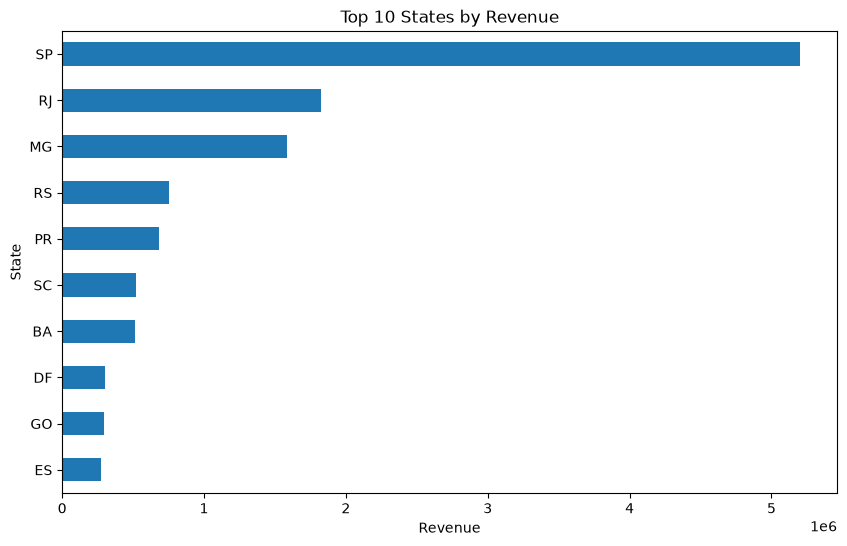

In [132]:
plt.figure(figsize=(10, 6))

state_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 States by Revenue")
plt.xlabel("Revenue")
plt.ylabel("State")

plt.show()

Average Order Value

In [135]:
total_revenue = customer_sales["revenue"].sum()
total_orders = customer_sales["order_id"].nunique()

aov = total_revenue / total_orders

print("Total Revenue: ₹", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Average Order Value (AOV): ₹", round(aov, 2))

Total Revenue: ₹ 13591643.7
Total Orders: 98666
Average Order Value (AOV): ₹ 137.75


In [136]:
segment_aov = (
    rfm.groupby("Customer_Segment")["Monetary"]
    .mean()
    .sort_values(ascending=False)
)

print(segment_aov)

Customer_Segment
Champions            277.684654
High Spenders        262.217570
At Risk              141.402038
Regular Customers    115.003323
Recent Customers      55.932462
Name: Monetary, dtype: float64


CUSTOMER LIFETIME VALUE(CLV)

In [137]:
customer_clv = (
    customer_sales.groupby("customer_unique_id")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Spending=("revenue", "sum")
    )
    .reset_index()
)

customer_clv["Average_Order_Value"] = (
    customer_clv["Total_Spending"] /
    customer_clv["Total_Orders"]
)

customer_clv.head()

,customer_unique_id,Total_Orders,Total_Spending,Average_Order_Value
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,18.90
2,0000f46a3911fa3c0805444483337064,1,69.00,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,180.00


In [138]:
top_clv_customers = (
    customer_clv
    .sort_values("Total_Spending", ascending=False)
    .head(10)
)

top_clv_customers

,customer_unique_id,Total_Orders,Total_Spending,Average_Order_Value
3799,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,13440.0
81388,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,3694.0
44139,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,7160.0
82230,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,6735.0
26015,459bef486812aa25204be022145caa62,1,6729.0,6729.0
95131,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0,6499.0
23947,4007669dec559734d6f53e029e360987,1,5934.6,5934.6
89056,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0,4690.0
34820,5d0a2980b292d049061542014e8960bf,1,4599.9,4599.9
27242,48e1ac109decbb87765a3eade6854098,1,4590.0,4590.0


PRODUCT ANALYSIS

In [145]:
print(sales.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'revenue']


Top categories by revenue

In [146]:
category_revenue = (
    sales.groupby("product_category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue.head(10))

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: revenue, dtype: float64


Top categories by quantity sold

In [147]:
category_quantity = (
    sales.groupby("product_category_name")["order_item_id"]
    .count()
    .sort_values(ascending=False)
)

print(category_quantity.head(10))

product_category_name
cama_mesa_banho           11115
beleza_saude               9670
esporte_lazer              8641
moveis_decoracao           8334
informatica_acessorios     7827
utilidades_domesticas      6964
relogios_presentes         5991
telefonia                  4545
ferramentas_jardim         4347
automotivo                 4235
Name: order_item_id, dtype: int64


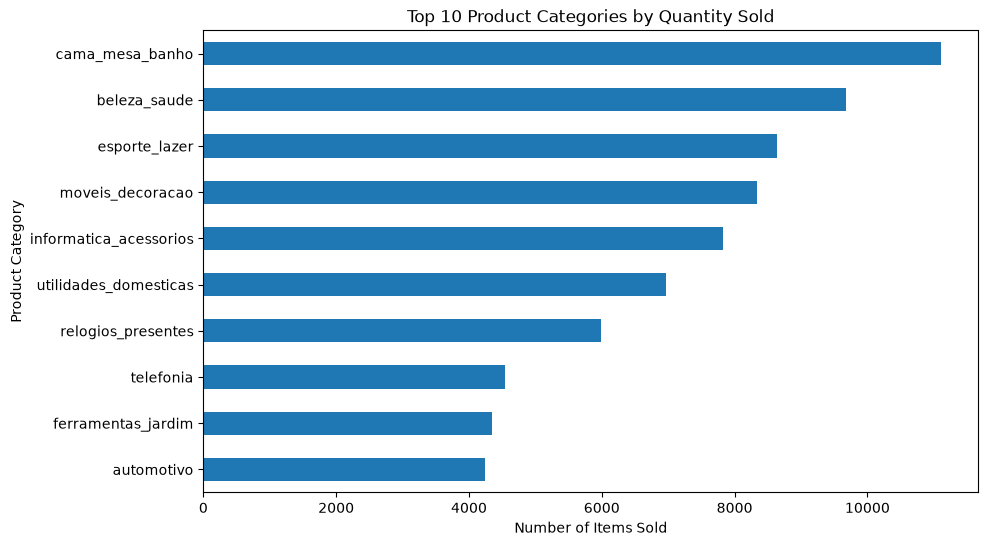

In [148]:
plt.figure(figsize=(10, 6))

category_quantity.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Quantity Sold")
plt.xlabel("Number of Items Sold")
plt.ylabel("Product Category")

plt.show()

Average price by category

In [150]:
category_avg_price = (
    sales.groupby("product_category_name")["price"]
    .mean()
    .sort_values(ascending=False)
)

print(category_avg_price.head(10))

product_category_name
pcs                                              1098.340542
portateis_casa_forno_e_cafe                       624.285658
eletrodomesticos_2                                476.124958
agro_industria_e_comercio                         342.124858
instrumentos_musicais                             281.616000
eletroportateis                                   280.778468
portateis_cozinha_e_preparadores_de_alimentos     264.568667
telefonia_fixa                                    225.693182
construcao_ferramentas_seguranca                  208.992371
relogios_presentes                                201.135984
Name: price, dtype: float64


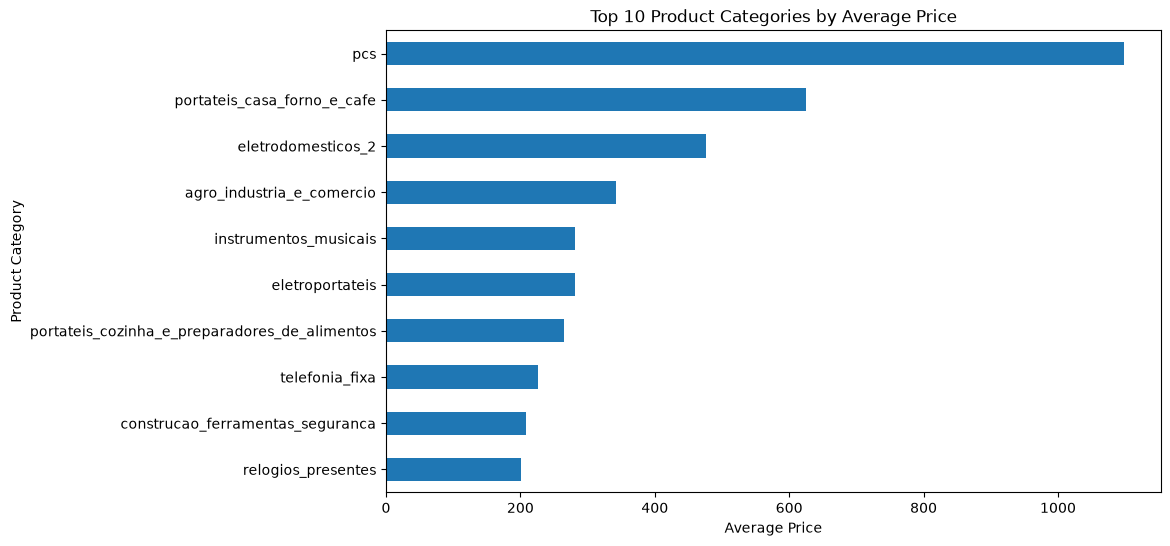

In [151]:
plt.figure(figsize=(10, 6))

category_avg_price.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Average Price")
plt.xlabel("Average Price")
plt.ylabel("Product Category")

plt.show()

In [153]:
sales["revenue"] = sales["price"]

sales["month"] = sales["order_purchase_timestamp"].dt.to_period("M")

print(sales[["order_purchase_timestamp", "month", "price", "revenue"]].head())

  order_purchase_timestamp    month   price  revenue
0      2017-10-02 10:56:33  2017-10   29.99    29.99
1      2018-07-24 20:41:37  2018-07  118.70   118.70
2      2018-08-08 08:38:49  2018-08  159.90   159.90
3      2017-11-18 19:28:06  2017-11   45.00    45.00
4      2018-02-13 21:18:39  2018-02   19.90    19.90


Monthly revenue trend of top categories

In [155]:
category_monthly_sales = (
    sales.groupby(["month", "product_category_name"])["revenue"]
    .sum()
    .reset_index()
)

category_monthly_sales.head()

,month,product_category_name,revenue
0,2016-09,beleza_saude,134.97
1,2016-09,moveis_decoracao,72.89
2,2016-09,telefonia,59.50
3,2016-10,alimentos,79.90
4,2016-10,audio,156.99


In [156]:
top_5_categories = (
    sales.groupby("product_category_name")["revenue"]
    .sum()
    .nlargest(5)
    .index
)

print(top_5_categories)

Index(['beleza_saude', 'relogios_presentes', 'cama_mesa_banho',
       'esporte_lazer', 'informatica_acessorios'],
      dtype='str', name='product_category_name')


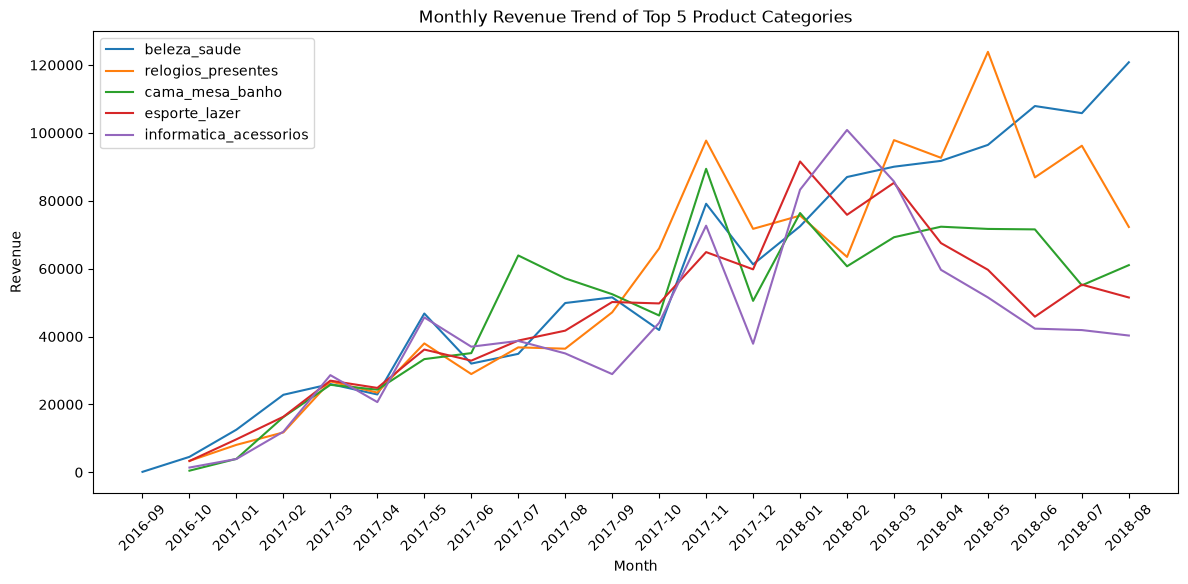

In [157]:
top_category_trend = category_monthly_sales[
    category_monthly_sales["product_category_name"].isin(top_5_categories)
]

plt.figure(figsize=(14, 6))

for category in top_5_categories:
    category_data = top_category_trend[
        top_category_trend["product_category_name"] == category
    ]
    
    plt.plot(
        category_data["month"].astype(str),
        category_data["revenue"],
        label=category
    )

plt.title("Monthly Revenue Trend of Top 5 Product Categories")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend()

plt.show()

SELLER ANALYSIS

In [158]:
sellers = pd.read_csv("../data/sellers_dataset.csv")

print("Sellers:", sellers.shape)
print(sellers.head())

Sellers: (3095, 4)
                          seller_id  seller_zip_code_prefix  \
0  3442f8959a84dea7ee197c632cb2df15                   13023   
1  d1b65fc7debc3361ea86b5f14c68d2e2                   13844   
2  ce3ad9de960102d0677a81f5d0bb7b2d                   20031   
3  c0f3eea2e14555b6faeea3dd58c1b1c3                    4195   
4  51a04a8a6bdcb23deccc82b0b80742cf                   12914   

         seller_city seller_state  
0           campinas           SP  
1         mogi guacu           SP  
2     rio de janeiro           RJ  
3          sao paulo           SP  
4  braganca paulista           SP  


In [159]:
print(sellers.columns.tolist())

['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']


In [160]:
print(sellers.isnull().sum())

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64


In [161]:
seller_sales = sales.merge(
    sellers,
    on="seller_id",
    how="left"
)

print("Seller Sales shape:", seller_sales.shape)
print(seller_sales.head())

Seller Sales shape: (112650, 27)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018

In [162]:
print("Missing seller IDs after merge:",
      seller_sales["seller_id"].isnull().sum())

print("Missing seller cities:",
      seller_sales["seller_city"].isnull().sum())

print("Missing seller states:",
      seller_sales["seller_state"].isnull().sum())

Missing seller IDs after merge: 0
Missing seller cities: 0
Missing seller states: 0


Top sellers by revenue

In [163]:
seller_revenue = (
    seller_sales.groupby("seller_id")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(seller_revenue.head(10))

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    229472.63
53243585a1d6dc2643021fd1853d8905    222776.05
4a3ca9315b744ce9f8e9374361493884    200472.92
fa1c13f2614d7b5c4749cbc52fecda94    194042.03
7c67e1448b00f6e969d365cea6b010ab    187923.89
7e93a43ef30c4f03f38b393420bc753a    176431.87
da8622b14eb17ae2831f4ac5b9dab84a    160236.57
7a67c85e85bb2ce8582c35f2203ad736    141745.53
1025f0e2d44d7041d6cf58b6550e0bfa    138968.55
955fee9216a65b617aa5c0531780ce60    135171.70
Name: revenue, dtype: float64


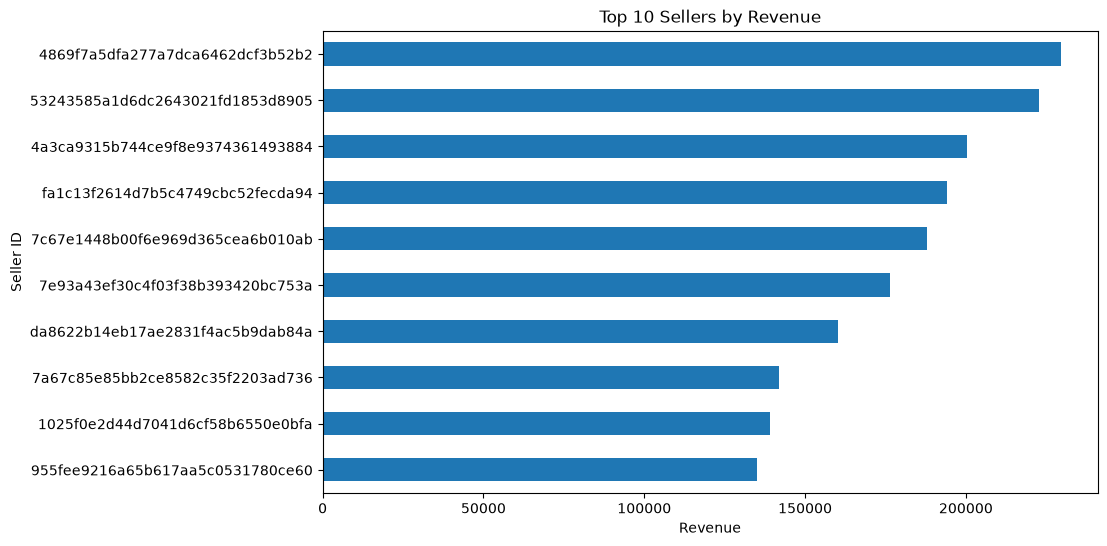

In [164]:
plt.figure(figsize=(10, 6))

seller_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Seller ID")

plt.show()

Top sellers by order volume

In [165]:
seller_orders = (
    seller_sales.groupby("seller_id")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(seller_orders.head(10))

seller_id
6560211a19b47992c3666cc44a7e94c0    1854
4a3ca9315b744ce9f8e9374361493884    1806
cc419e0650a3c5ba77189a1882b7556a    1706
1f50f920176fa81dab994f9023523100    1404
da8622b14eb17ae2831f4ac5b9dab84a    1314
955fee9216a65b617aa5c0531780ce60    1287
7a67c85e85bb2ce8582c35f2203ad736    1160
ea8482cd71df3c1969d7b9473ff13abc    1146
4869f7a5dfa277a7dca6462dcf3b52b2    1132
3d871de0142ce09b7081e2b9d1733cb1    1080
Name: order_id, dtype: int64


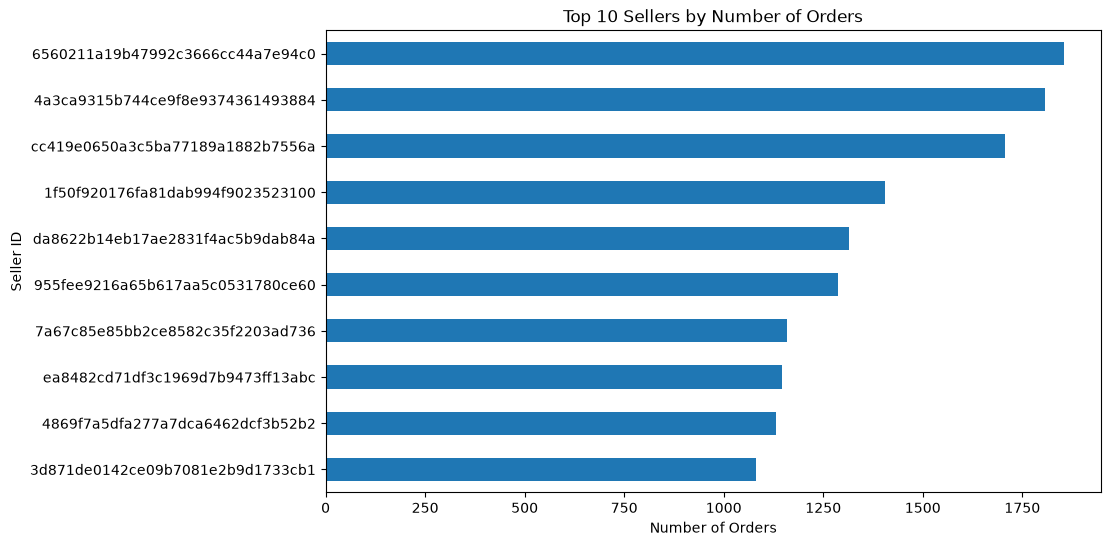

In [166]:
plt.figure(figsize=(10, 6))

seller_orders.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Sellers by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Seller ID")

plt.show()

Seller AOV

In [167]:
seller_aov = (
    seller_sales.groupby("seller_id")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Total_Orders=("order_id", "nunique")
    )
)

seller_aov["Average_Order_Value"] = (
    seller_aov["Total_Revenue"] /
    seller_aov["Total_Orders"]
)

seller_aov = seller_aov.sort_values(
    "Average_Order_Value",
    ascending=False
)

print(seller_aov.head(10))

                                  Total_Revenue  Total_Orders  \
seller_id                                                       
80ceebb4ee9b31afb6c6a916a574a1e2        6729.00             1   
ee27a8f15b1dded4d213a468ba4eb391        6499.00             1   
b37c4c02bda3161a7546a4e6d222d5b2       24075.00             4   
585175ec331ea177fa47199e39a6170a        3549.00             1   
abe021b01ba992245271b9aa422032df        6720.00             2   
a00824eb9093d40e589b940ec45c4eb0        9399.97             3   
e2a1ac9bf33e5549a2a4f834e70df2f8       14999.45             5   
e908c0f3646e8b60375734a350d95d71        2951.00             1   
d63c73efd41eb002280e7ec831424edb        5598.00             2   
1444c08e64d55fb3c25f0f09c07ffcf2        2749.00             1   

                                  Average_Order_Value  
seller_id                                              
80ceebb4ee9b31afb6c6a916a574a1e2          6729.000000  
ee27a8f15b1dded4d213a468ba4eb391          6499.0000

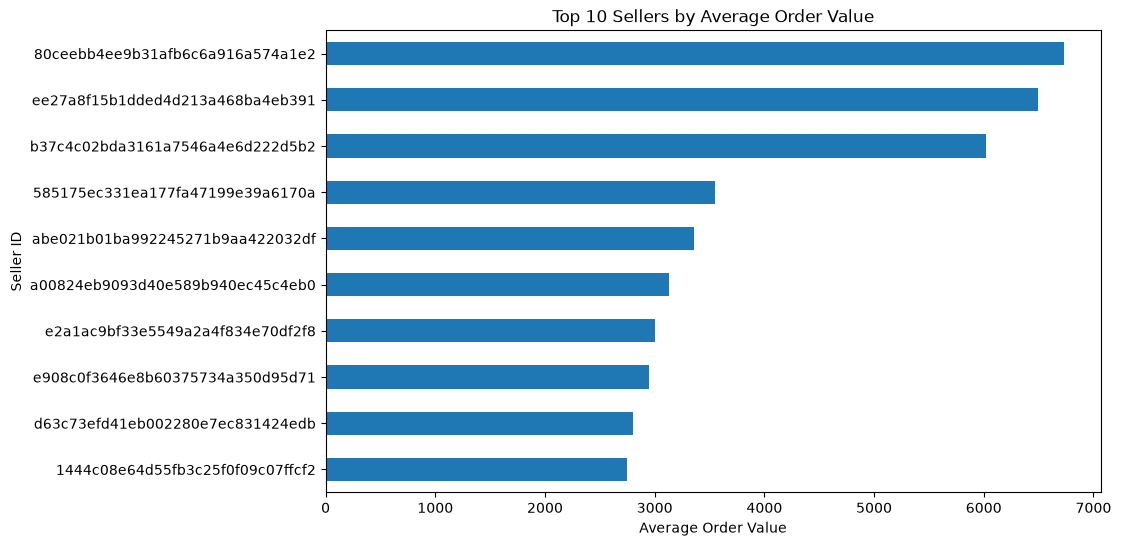

In [168]:
plt.figure(figsize=(10, 6))

seller_aov["Average_Order_Value"].head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Sellers by Average Order Value")
plt.xlabel("Average Order Value")
plt.ylabel("Seller ID")

plt.show()

Seller revenue by state

In [169]:
seller_state_revenue = (
    seller_sales.groupby("seller_state")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(seller_state_revenue)

seller_state
SP    8753396.21
PR    1261887.21
MG    1011564.74
RJ     843984.22
SC     632426.07
RS     378559.54
BA     285561.56
DF      97749.48
PE      91493.85
GO      66399.21
ES      47689.61
MA      36408.95
CE      20240.64
PB      17095.00
MT      17070.72
RN       9992.60
MS       8551.69
RO       4762.20
PI       2522.00
SE       1606.20
PA       1238.00
AM       1177.00
AC        267.00
Name: revenue, dtype: float64


In [170]:
print(seller_state_revenue.head(10))

seller_state
SP    8753396.21
PR    1261887.21
MG    1011564.74
RJ     843984.22
SC     632426.07
RS     378559.54
BA     285561.56
DF      97749.48
PE      91493.85
GO      66399.21
Name: revenue, dtype: float64


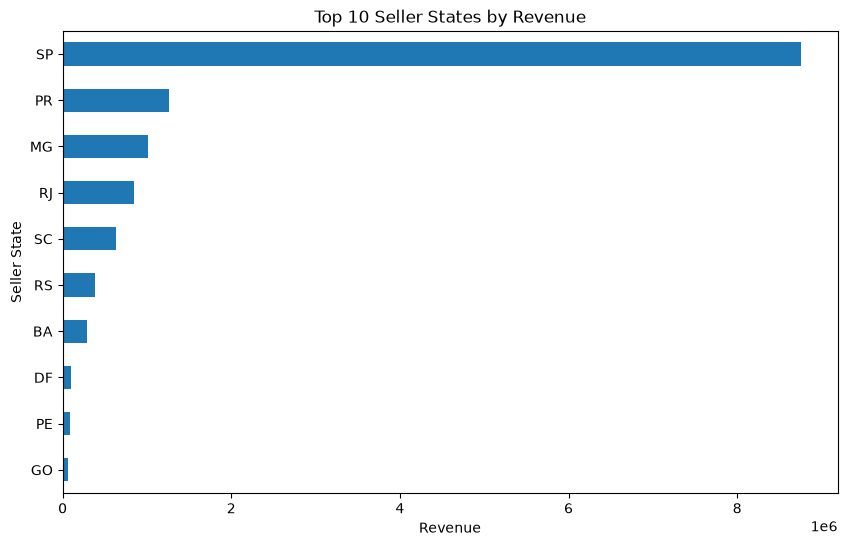

In [171]:
plt.figure(figsize=(10, 6))

seller_state_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Seller States by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Seller State")

plt.show()

DELIVERY ANALYSIS

In [172]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days

print(orders["delivery_days"].describe())

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64


In [173]:
print("Average Delivery Time:",
      round(orders["delivery_days"].mean(), 2), "days")

print("Minimum Delivery Time:",
      orders["delivery_days"].min(), "days")

print("Maximum Delivery Time:",
      orders["delivery_days"].max(), "days")

Average Delivery Time: 12.09 days
Minimum Delivery Time: 0.0 days
Maximum Delivery Time: 209.0 days


Late-delivery indicato

In [174]:
orders["late_delivery"] = (
    orders["order_delivered_customer_date"]
    > orders["order_estimated_delivery_date"]
)

print(orders["late_delivery"].value_counts())

late_delivery
False    91614
True      7827
Name: count, dtype: int64


Late-delivery rate

In [175]:
delivered_orders = orders[
    orders["order_delivered_customer_date"].notna()
]

late_orders = delivered_orders["late_delivery"].sum()

late_percentage = (
    late_orders / len(delivered_orders)
) * 100

print("Delivered Orders:", len(delivered_orders))
print("Late Orders:", late_orders)
print("Late Delivery Rate:", round(late_percentage, 2), "%")

Delivered Orders: 96476
Late Orders: 7827
Late Delivery Rate: 8.11 %


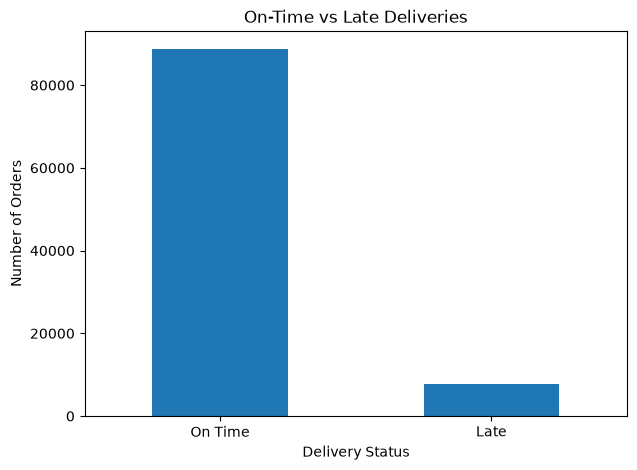

In [176]:
plt.figure(figsize=(7, 5))

delivered_orders["late_delivery"].value_counts().rename(
    {False: "On Time", True: "Late"}
).plot(kind="bar")

plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

In [178]:
delivery_state = customer_sales.merge(
    orders[["order_id", "delivery_days", "late_delivery"]],
    on="order_id",
    how="left"
)

print(delivery_state[[
    "order_id",
    "customer_state",
    "delivery_days",
    "late_delivery"
]].head())

                           order_id customer_state  delivery_days  \
0  e481f51cbdc54678b7cc49136f2d6af7             SP            8.0   
1  53cdb2fc8bc7dce0b6741e2150273451             BA           13.0   
2  47770eb9100c2d0c44946d9cf07ec65d             GO            9.0   
3  949d5b44dbf5de918fe9c16f97b45f8a             RN           13.0   
4  ad21c59c0840e6cb83a9ceb5573f8159             SP            2.0   

   late_delivery  
0          False  
1          False  
2          False  
3          False  
4          False  


In [179]:
state_delivery = (
    delivery_state
    .dropna(subset=["delivery_days"])
    .groupby("customer_state")["delivery_days"]
    .mean()
    .sort_values(ascending=False)
)

print(state_delivery)

customer_state
RR    27.826087
AP    27.753086
AM    25.963190
AL    23.992974
PA    23.301708
MA    21.203750
SE    20.978667
CE    20.537167
AC    20.329670
PB    20.119454
RO    19.282051
PI    18.931166
RN    18.873321
BA    18.774640
PE    17.792096
MT    17.508197
TO    17.003226
ES    15.192809
MS    15.107275
GO    14.948177
RS    14.708299
RJ    14.689382
SC    14.520986
DF    12.501486
MG    11.515522
PR    11.480793
SP     8.259609
Name: delivery_days, dtype: float64


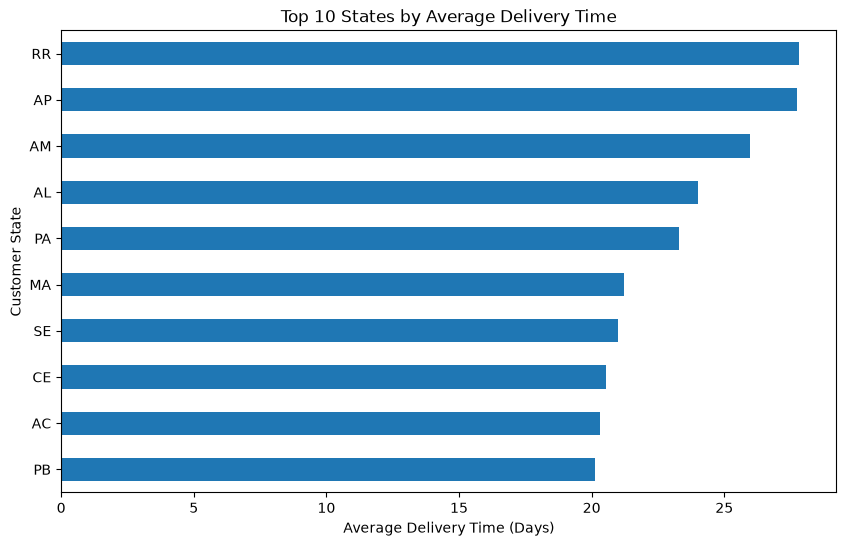

In [180]:
plt.figure(figsize=(10, 6))

state_delivery.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 States by Average Delivery Time")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("Customer State")

plt.show()

REVIEW ANALYSIS

In [181]:
print(reviews["review_score"].value_counts().sort_index())

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [182]:
average_review = reviews["review_score"].mean()

print("Average Review Score:", round(average_review, 2))

Average Review Score: 4.09


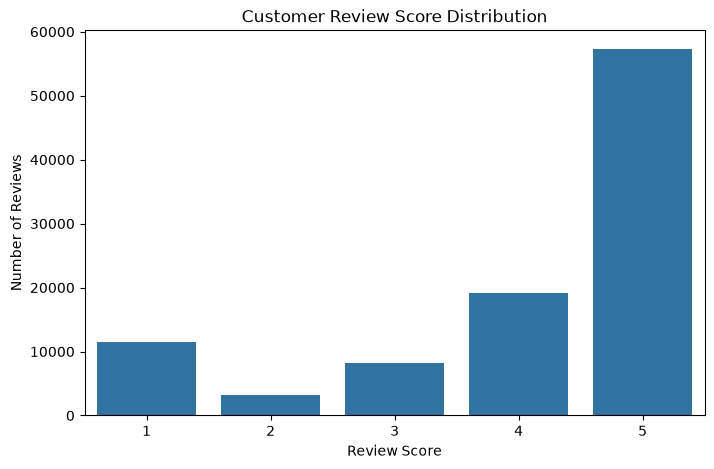

In [183]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="review_score",
    order=[1, 2, 3, 4, 5]
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

In [184]:
review_percentage = (
    reviews["review_score"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(review_percentage.round(2))

review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: proportion, dtype: float64


MERGE REVIEWS WITH DELIVERY DATA

In [186]:
delivery_reviews = delivery_state.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="left"
)

print(delivery_reviews.shape)
print(delivery_reviews[[
    "order_id",
    "delivery_days",
    "late_delivery",
    "review_score"
]].head())

(113314, 30)
                           order_id  delivery_days  late_delivery  \
0  e481f51cbdc54678b7cc49136f2d6af7            8.0          False   
1  53cdb2fc8bc7dce0b6741e2150273451           13.0          False   
2  47770eb9100c2d0c44946d9cf07ec65d            9.0          False   
3  949d5b44dbf5de918fe9c16f97b45f8a           13.0          False   
4  ad21c59c0840e6cb83a9ceb5573f8159            2.0          False   

   review_score  
0           4.0  
1           4.0  
2           5.0  
3           5.0  
4           5.0  


In [187]:
review_by_delivery = (
    delivery_reviews
    .dropna(subset=["review_score"])
    .groupby("late_delivery")["review_score"]
    .mean()
)

review_by_delivery.index = ["On Time" if x == False else "Late"
                            for x in review_by_delivery.index]

print(review_by_delivery.round(2))

On Time    4.15
Late       2.55
Name: review_score, dtype: float64


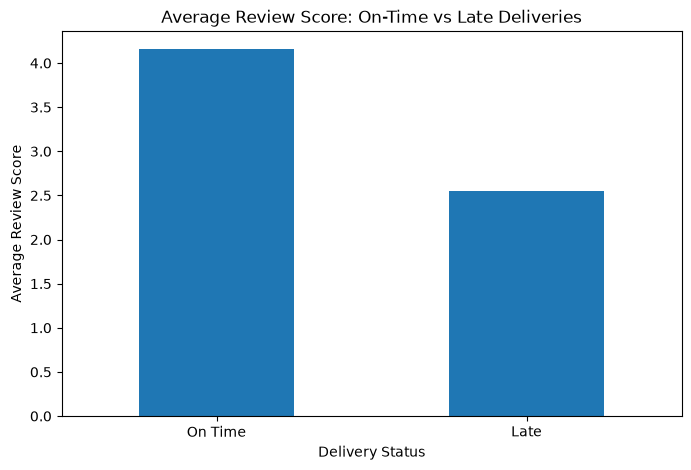

In [188]:
plt.figure(figsize=(8, 5))

review_by_delivery.plot(kind="bar")

plt.title("Average Review Score: On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.xticks(rotation=0)

plt.show()

Merge reviews with your sales data

In [189]:
category_reviews = sales.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="left"
)

print(category_reviews.shape)

(113314, 25)


In [190]:
category_review_score = (
    category_reviews
    .dropna(subset=["review_score"])
    .groupby("product_category_name")["review_score"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 categories by average review score:")
print(category_review_score.head(10))

Top 10 categories by average review score:
product_category_name
cds_dvds_musicais                     4.642857
fashion_roupa_infanto_juvenil         4.500000
livros_interesse_geral                4.446266
construcao_ferramentas_ferramentas    4.444444
flores                                4.419355
livros_importados                     4.400000
livros_tecnicos                       4.368421
alimentos_bebidas                     4.315412
malas_acessorios                      4.315257
portateis_casa_forno_e_cafe           4.302632
Name: review_score, dtype: float64


In [191]:
print("Bottom 10 categories by average review score:")
print(category_review_score.tail(10))

Bottom 10 categories by average review score:
product_category_name
fashion_roupa_feminina                           3.780000
artigos_de_festas                                3.767442
telefonia_fixa                                   3.683206
fashion_roupa_masculina                          3.641221
casa_conforto_2                                  3.629630
moveis_escritorio                                3.493183
pc_gamer                                         3.333333
portateis_cozinha_e_preparadores_de_alimentos    3.266667
fraldas_higiene                                  3.256410
seguros_e_servicos                               2.500000
Name: review_score, dtype: float64


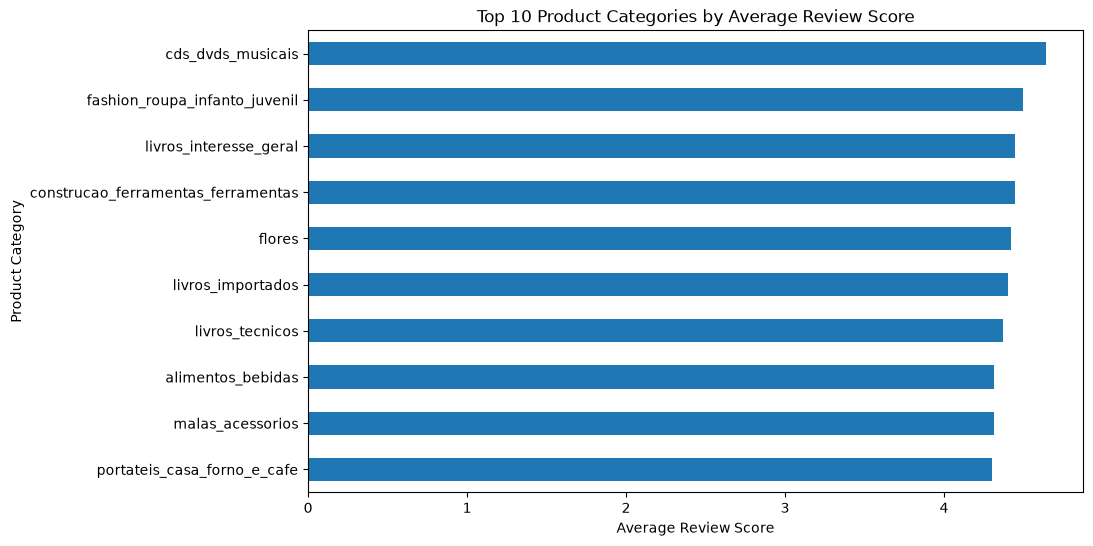

In [192]:
plt.figure(figsize=(10, 6))

category_review_score.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Average Review Score")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")

plt.show()

Delivery time VS review score 

In [193]:
delivery_reviews["delivery_group"] = pd.cut(
    delivery_reviews["delivery_days"],
    bins=[-1, 5, 10, 15, 20, float("inf")],
    labels=["0-5 days", "6-10 days", "11-15 days", "16-20 days", "20+ days"]
)

print(delivery_reviews["delivery_group"].value_counts().sort_index())

delivery_group
0-5 days      22300
6-10 days     37841
11-15 days    24379
16-20 days    12267
20+ days      14052
Name: count, dtype: int64


In [194]:
delivery_review_analysis = (
    delivery_reviews
    .dropna(subset=["review_score", "delivery_group"])
    .groupby("delivery_group", observed=True)["review_score"]
    .mean()
)

print(delivery_review_analysis.round(2))

delivery_group
0-5 days      4.35
6-10 days     4.26
11-15 days    4.16
16-20 days    4.01
20+ days      3.08
Name: review_score, dtype: float64


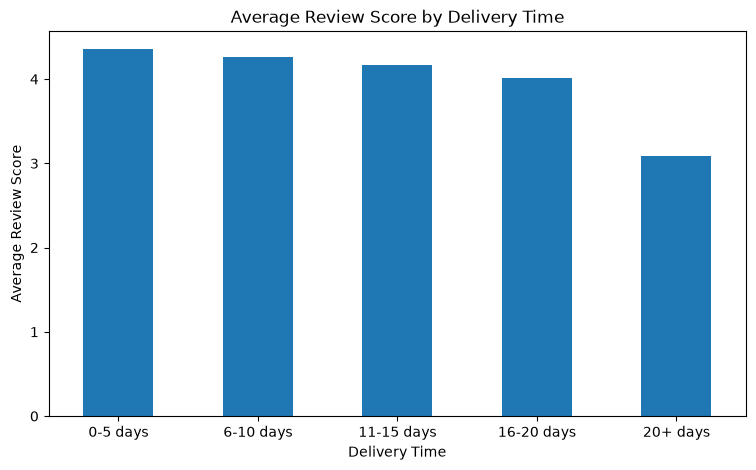

In [195]:
plt.figure(figsize=(9, 5))

delivery_review_analysis.plot(kind="bar")

plt.title("Average Review Score by Delivery Time")
plt.xlabel("Delivery Time")
plt.ylabel("Average Review Score")
plt.xticks(rotation=0)

plt.show()

ML COMPONENT

In [196]:
rfm_ml = rfm[["customer_unique_id", "Recency", "Frequency", "Monetary"]].copy()

print(rfm_ml.shape)
print(rfm_ml.head())

(95420, 4)
                 customer_unique_id  Recency  Frequency  Monetary
0  0000366f3b9a7992bf8c76cfdf3221e2      160          1    129.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f      163          1     18.90
2  0000f46a3911fa3c0805444483337064      585          1     69.00
3  0000f6ccb0745a6a4b88665a16c9f078      369          1     25.99
4  0004aac84e0df4da2b147fca70cf8255      336          1    180.00


In [197]:
print(rfm_ml[["Recency", "Frequency", "Monetary"]].describe())

            Recency     Frequency      Monetary
count  95420.000000  95420.000000  95420.000000
mean     287.128118      1.034018    142.440198
std      153.157768      0.211234    217.656355
min       44.000000      1.000000      0.850000
25%      163.000000      1.000000     47.900000
50%      268.000000      1.000000     89.900000
75%      396.000000      1.000000    155.000000
max      772.000000     16.000000  13440.000000


In [198]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_ml[["Recency", "Frequency", "Monetary"]]
)

print(rfm_scaled[:5])

[[-0.83005117 -0.16104511 -0.05761497]
 [-0.81046342 -0.16104511 -0.56759586]
 [ 1.94487976 -0.16104511 -0.33741529]
 [ 0.53456192 -0.16104511 -0.5350214 ]
 [ 0.3190967  -0.16104511  0.1725656 ]]


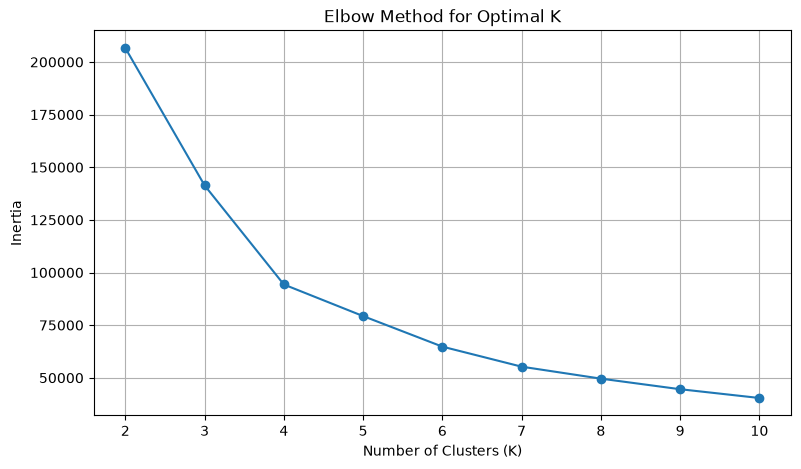

In [201]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(K_range, inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(K_range)
plt.grid()

plt.show()

In [202]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm_ml["Cluster"] = kmeans.fit_predict(rfm_scaled)

print(rfm_ml["Cluster"].value_counts().sort_index())

Cluster
0     2268
1    51976
2     2883
3    38293
Name: count, dtype: int64


In [203]:
cluster_summary = (
    rfm_ml.groupby("Cluster")
    .agg(
        Customers=("customer_unique_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,2268,287.83,1.01,1146.41
1,51976,177.27,1.00,113.55
2,2883,269.70,2.11,243.05
3,38293,437.51,1.00,114.61


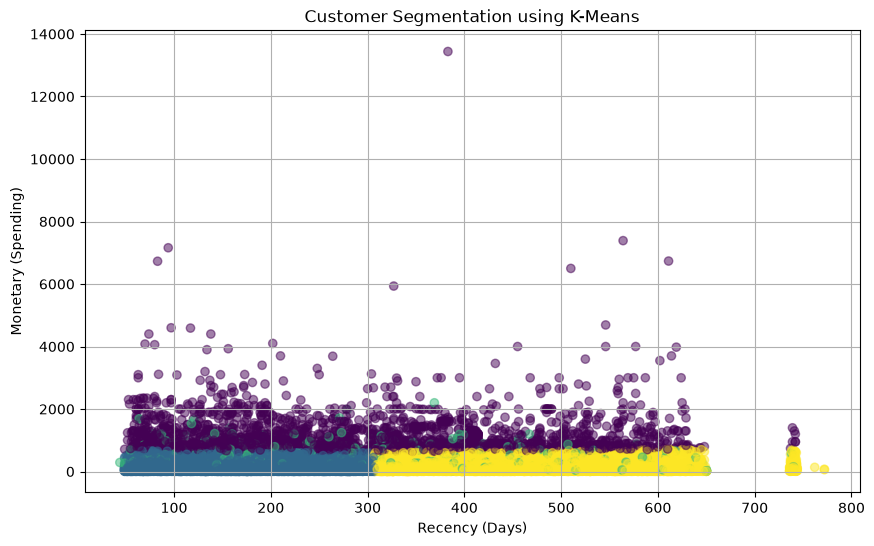

In [204]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rfm_ml["Recency"],
    rfm_ml["Monetary"],
    c=rfm_ml["Cluster"],
    alpha=0.5
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary (Spending)")
plt.grid()

plt.show()

In [205]:
cluster_summary.sort_values("Avg_Monetary", ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,2268,287.83,1.01,1146.41
2,2883,269.70,2.11,243.05
3,38293,437.51,1.00,114.61
1,51976,177.27,1.00,113.55


In [206]:
cluster_names = {
    0: "Very High Spenders",
    1: "Recent Low-Value",
    2: "Repeat Buyers",
    3: "Inactive Customers"
}

rfm_ml["Cluster_Name"] = rfm_ml["Cluster"].map(cluster_names)

print(rfm_ml["Cluster_Name"].value_counts())

Cluster_Name
Recent Low-Value      51976
Inactive Customers    38293
Repeat Buyers          2883
Very High Spenders     2268
Name: count, dtype: int64


In [207]:
final_cluster_summary = (
    rfm_ml.groupby("Cluster_Name")
    .agg(
        Customers=("customer_unique_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
    .sort_values("Avg_Monetary", ascending=False)
)

final_cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster_Name,,,,
Very High Spenders,2268,287.83,1.01,1146.41
Repeat Buyers,2883,269.70,2.11,243.05
Inactive Customers,38293,437.51,1.00,114.61
Recent Low-Value,51976,177.27,1.00,113.55


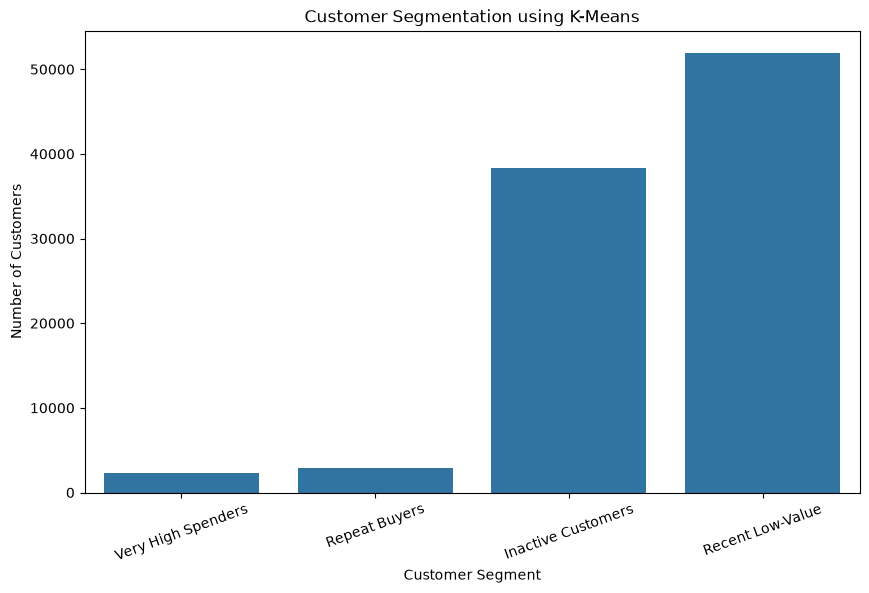

In [208]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_cluster_summary.reset_index(),
    x="Cluster_Name",
    y="Customers"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

In [209]:
sales_powerbi = sales.copy()

sales_powerbi.to_csv(
    "../powerbi/sales_analysis.csv",
    index=False
)

print("Sales analysis exported successfully!")
print("Shape:", sales_powerbi.shape)

Sales analysis exported successfully!
Shape: (112650, 24)


In [210]:
customer_powerbi = customer_sales.copy()

customer_powerbi.to_csv(
    "../powerbi/customer_analysis.csv",
    index=False
)

print("Customer analysis exported successfully!")
print("Shape:", customer_powerbi.shape)

Customer analysis exported successfully!
Shape: (112650, 27)


In [211]:
rfm_powerbi = rfm_ml.copy()

rfm_powerbi.to_csv(
    "../powerbi/rfm_analysis.csv",
    index=False
)

print("RFM analysis exported successfully!")
print("Shape:", rfm_powerbi.shape)
print(rfm_powerbi.head())

RFM analysis exported successfully!
Shape: (95420, 6)
                 customer_unique_id  Recency  Frequency  Monetary  Cluster  \
0  0000366f3b9a7992bf8c76cfdf3221e2      160          1    129.90        1   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      163          1     18.90        1   
2  0000f46a3911fa3c0805444483337064      585          1     69.00        3   
3  0000f6ccb0745a6a4b88665a16c9f078      369          1     25.99        3   
4  0004aac84e0df4da2b147fca70cf8255      336          1    180.00        3   

         Cluster_Name  
0    Recent Low-Value  
1    Recent Low-Value  
2  Inactive Customers  
3  Inactive Customers  
4  Inactive Customers  


In [212]:
seller_powerbi = seller_sales.copy()

seller_powerbi.to_csv(
    "../powerbi/seller_analysis.csv",
    index=False
)

print("Seller analysis exported successfully!")
print("Shape:", seller_powerbi.shape)

Seller analysis exported successfully!
Shape: (112650, 27)


In [ ]:
delivery_reviews_powerbi = delivery_reviews.copy()

delivery_reviews_powerbi.to_csv(
    "../powerbi/delivery_reviews.csv",
    index=False
)

print("Delivery & Review analysis exported successfully!")
print("Shape:", delivery_reviews_powerbi.shape)

Delivery & Review analysis exported successfully!
Shape: (113314, 31)


: 